In [1]:
from dotenv import load_dotenv
from langchain_groq import ChatGroq


load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
)


## Tools

In [2]:
from langchain.tools import tool

In [3]:
@tool
def tool_duckduckgo_search(query: str) -> str:
    
    """Use this tool when you need to answer questions about current events or general knowledge. """

    from langchain_community.tools import DuckDuckGoSearchRun

    search = DuckDuckGoSearchRun()

    response = search.invoke(query)

    return response


In [4]:
tool_duckduckgo_search.invoke("What is the capital of France?")

C:\Users\Pinakesh\AppData\Local\Temp\ipykernel_17756\2405146460.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


'Paris[b] is the capital and largest city of France, with an estimated city population of 2.04 million in an area of 105.4 km2 (40.7 sq mi), as of January 2026, [4] and a metropolitan population of 13.3 million (2023). Located on the Seine in the centre of the Île-de-France region, it is the largest metropolitan area and fourth-most populous city in the European Union (EU). Paris is nicknamed ... Capital of France This article is about the French national capital in general. For the current capital, see Paris. The capital of France is Paris. [1] In the course of history, the national capital has been in many locations other than Paris. France, [j] officially the French Republic, [k] is a country primarily located in Western Europe. [l] Its overseas regions and territories include French Guiana in South America, Saint Pierre and Miquelon in the North Atlantic, the French West Indies, and many islands in Oceania and the Indian Ocean. Metropolitan France shares borders with Belgium and Lu

In [5]:
from langchain_core.tools import tool
import wikipedia as wiki_pkg

# Wikipedia requires a descriptive User-Agent
wiki_pkg.wikipedia.USER_AGENT = "GenAI-Practice/1.0 (https://github.com/PinakeshCrafts)"

@tool
def tool_wikipedia_search(query: str) -> str:
    """Use this tool when you need to answer questions about persons, places, etc."""
    from langchain_community.tools import WikipediaQueryRun
    from langchain_community.utilities import WikipediaAPIWrapper

    wikipedia = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wikipedia.invoke(query)

In [6]:
tool_wikipedia_search.invoke("Sam Altman")

'Page: Sam Altman\nSummary: Samuel Harris Altman (born April 22, 1985) is an American entrepreneur and investor who has been the chief executive officer (CEO) of the artificial intelligence company OpenAI since 2019.\nAltman attended Stanford University for two years before he dropped out and co-founded Loopt, a geosocial networking application for smartphones. Loopt was acquired by Green Dot Corporation for $43.4 million in March 2012. In 2011, Altman joined Y Combinator, a technology startup accelerator and venture capital firm, and was the company\'s president from 2014 to 2019. He is a billionaire, due to investments in over 400 companies including Reddit, Worldcoin, Helion Energy and Instacart.\nAltman co-founded OpenAI in 2015 and became its CEO in 2019, a role that made him a prominent figure of the AI boom. He supervised the launch of ChatGPT in November 2022. In 2023, he was ousted by the organization\'s board of directors for not being "consistently candid". The move was met 

In [7]:
@tool
def tool_arxiv_search(query: str) -> str:
    """Use this tool when you need to answer questions about scientific papers or research topics."""

    from langchain_community.tools import ArxivQueryRun
    from langchain_community.utilities import ArxivAPIWrapper

    arxiv_wrapper = ArxivAPIWrapper(
        top_k_results=3,            # Number of papers to retrieve
        doc_content_chars_max=2000  # Max characters per document
    )
    arxiv_tool = ArxivQueryRun(api_wrapper=arxiv_wrapper)

    # FIX: return the result (it used to only print, so the LLM received None)
    return arxiv_tool.invoke(query)

In [8]:
# Single source of truth for the student records
STUDENTS = [
    {"name": "Pinakesh Chattopadhyay", "age": 30, "College": "VIT", "CGPA": 8.6},
    {"name": "Aarav Sharma",          "age": 21, "College": "IIT Kharagpur", "CGPA": 9.1},
    {"name": "Ananya Das",            "age": 22, "College": "Jadavpur University", "CGPA": 8.8},
    {"name": "Rohan Gupta",           "age": 20, "College": "NIT Durgapur", "CGPA": 7.9},
    {"name": "Priya Sen",             "age": 23, "College": "BITS Pilani", "CGPA": 8.4},
    {"name": "Arjun Mehta",           "age": 22, "College": "IIIT Hyderabad", "CGPA": 9.3},
    {"name": "Sneha Roy",             "age": 21, "College": "SRM University", "CGPA": 7.5},
    {"name": "Vikram Singh",          "age": 24, "College": "Manipal Institute of Technology", "CGPA": 8.0},
    {"name": "Ishita Ghosh",          "age": 20, "College": "Presidency University", "CGPA": 8.9},
    {"name": "Kabir Khan",            "age": 25, "College": "IIEST Shibpur", "CGPA": 7.2},
    {"name": "Meera Nair",            "age": 22, "College": "VIT", "CGPA": 9.0},
    {"name": "Tanvi Joshi",           "age": 21, "College": "Heritage Institute of Technology", "CGPA": 8.2},
    {"name": "Siddharth Bose",        "age": 23, "College": "Techno India University", "CGPA": 6.9},
]

@tool
def tool_personal_info(name: str) -> str:
    """Use this tool to look up ONE specific person's age, college and CGPA by name.
    For questions about all students (charts, averages, distributions) use tool_all_students instead.
    Args:
        name (str): The name (or part of the name) of the person to look up.
    Returns:
        str: The person's age, college and CGPA, or a message if the information is not found.
    """
    name = name.strip().lower()
    if not name:
        return "Error: please provide a name."

    matches = [i for i in STUDENTS if name in i["name"].lower()]
    if not matches:
        return "Information not found."

    return "\n".join(
        f"{i['name']} is {i['age']} years old, studies at {i['College']} and has a CGPA of {i['CGPA']}."
        for i in matches
    )


@tool
def tool_all_students() -> str:
    """Use this tool to get the data of ALL students in the database (name, age, college, CGPA).
    Use it for any question about all students, a group of students, averages, rankings,
    or when you need numbers to draw a chart (histogram, bar chart, line chart, etc.).
    Returns JSON with "names", "cgpa", "age" and "college" lists, in the same order.
    The database has NO semester field.
    """
    import json
    return json.dumps({
        "names":   [s["name"] for s in STUDENTS],
        "cgpa":    [s["CGPA"] for s in STUDENTS],
        "age":     [s["age"] for s in STUDENTS],
        "college": [s["College"] for s in STUDENTS],
    })

In [9]:
tool_personal_info.invoke("Pinakesh Chattopadhyay")

'Pinakesh Chattopadhyay is 30 years old, studies at VIT and has a CGPA of 8.6.'

## Tool for creating charts

In [10]:
from langchain_core.tools import tool

@tool
def tool_create_chart(chart_type: str, title: str, labels: list, data: dict,
                      x_label: str = "", y_label: str = "", bins: int = 10) -> str:
    """Use this tool when you need to create a chart or graph from numbers.
    Call it only AFTER you have the numbers (for example from a search or from another tool).
    Args:
        chart_type (str): One of line, bar, barh, stacked_bar, scatter, pie, area, hist, box.
        title (str): Title of the chart.
        labels (list): X-axis labels (names or numbers). Use an empty list for hist and box.
        data (dict): Series name -> list of numbers, like {"Sales": [10, 20, 30]}.
                     Each list must be the same length as labels (except hist and box).
                     For pie, use only one series.
        x_label (str): Optional X-axis label.
        y_label (str): Optional Y-axis label.
        bins (int): Number of bins. Only used for hist (histogram). Default 10.
    Returns:
        str: The file path of the saved chart image (PNG), or an error message.
    """
    import os
    import re
    import numpy as np
    from matplotlib.figure import Figure

    if not data:
        return "Error: data is empty."

    # Make sure every series is a clean list of floats
    try:
        data = {str(k): [float(v) for v in vals] for k, vals in data.items()}
    except (TypeError, ValueError):
        return "Error: every series in data must be a list of numbers."

    labels = list(labels or [])

    # Check lengths
    if chart_type not in ("hist", "box"):
        if not labels:
            return "Error: labels are required for this chart type."
        for name, values in data.items():
            if len(values) != len(labels):
                return f"Error: series '{name}' has {len(values)} values but labels has {len(labels)}."

    fig = Figure(figsize=(8, 5))
    ax = fig.subplots()
    names = list(data.keys())
    pos = np.arange(len(labels))
    str_labels = [str(l) for l in labels]

    if chart_type == "line":
        for name in names:
            ax.plot(str_labels, data[name], marker="o", label=name)

    elif chart_type == "scatter":
        for name in names:
            ax.scatter(str_labels, data[name], label=name)

    elif chart_type == "area":
        ax.stackplot(str_labels, *[data[n] for n in names], labels=names, alpha=0.8)

    elif chart_type in ("bar", "barh"):
        width = 0.8 / len(names)
        for i, name in enumerate(names):
            offset = pos + i * width - 0.4 + width / 2
            if chart_type == "bar":
                ax.bar(offset, data[name], width, label=name)
            else:
                ax.barh(offset, data[name], width, label=name)
        if chart_type == "bar":
            ax.set_xticks(pos)
            ax.set_xticklabels(str_labels)
        else:
            ax.set_yticks(pos)
            ax.set_yticklabels(str_labels)

    elif chart_type == "stacked_bar":
        bottom = np.zeros(len(labels))
        for name in names:
            ax.bar(str_labels, data[name], bottom=bottom, label=name)
            bottom += np.array(data[name])

    elif chart_type == "pie":
        ax.pie(data[names[0]], labels=str_labels, autopct="%1.1f%%", startangle=90)
        ax.axis("equal")

    elif chart_type == "hist":
        # all series share the same bin edges so overlapping histograms are comparable
        all_values = np.concatenate([data[n] for n in names])
        edges = np.histogram_bin_edges(all_values, bins=max(1, int(bins)))
        for name in names:
            ax.hist(data[name], bins=edges, alpha=0.7, edgecolor="black", label=name)
        if not y_label:
            y_label = "Frequency"
        from matplotlib.ticker import MaxNLocator
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))   # counts are whole numbers

    elif chart_type == "box":
        ax.boxplot([data[n] for n in names], tick_labels=names)

    else:
        return "Error: chart_type must be one of line, bar, barh, stacked_bar, scatter, pie, area, hist, box."

    ax.set_title(title)
    if x_label:
        ax.set_xlabel(x_label)
    if y_label:
        ax.set_ylabel(y_label)
    if chart_type not in ("pie", "box") and (len(names) > 1 or chart_type == "area"):
        ax.legend()
    if chart_type not in ("hist", "pie", "box", "barh"):
        ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()

    os.makedirs("charts", exist_ok=True)
    filename = re.sub(r"[^a-zA-Z0-9]+", "_", title).strip("_").lower() or "chart"
    path = f"charts/{filename}.png"
    fig.savefig(path, dpi=150)
    return path

In [11]:
import yfinance as yf

@tool
def tool_get_nifty_returns(years: int = 10) -> str:
    """Get monthly percentage returns of the Nifty 50 index for the last N years.
    Returns JSON with "labels" (YYYY-MM) and "values" (monthly % returns)."""
    import json
    try:
        close = yf.Ticker("^NSEI").history(period=f"{years}y", interval="1mo")["Close"]
    except Exception as e:
        return f"Error: could not download Nifty data ({e})."
    if close.empty:
        return "Error: no Nifty data returned."
    returns = (close.pct_change().dropna() * 100).round(2)
    return json.dumps({"labels": [d.strftime("%Y-%m") for d in returns.index],
                       "values": returns.tolist()})

## Bind Tools

In [12]:
toolkit = [
    tool_duckduckgo_search,
    tool_wikipedia_search,
    tool_arxiv_search,
    tool_personal_info,
    tool_all_students,
    tool_create_chart,
    tool_get_nifty_returns,
]

In [13]:
llm_bind = llm.bind_tools(toolkit)

## Run the tool-calling loop
`bind_tools` only lets the model *ask* for a tool call. Something still has to run the tools and hand the results back, otherwise the chart is never drawn. `run_agent` does that loop.

In [14]:
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from IPython.display import Image, display

tools_by_name = {t.name: t for t in toolkit}

SYSTEM_PROMPT = (
    "You are a data assistant. Use tools to get real numbers first, then call "
    "tool_create_chart to draw the graph. Never invent numbers.\n"
    "- Questions about students (all students, CGPA, age, colleges) must use "
    "tool_all_students or tool_personal_info. NEVER web-search for student data; "
    "it only exists in these tools.\n"
    "- The student database has no semester field. If the user mentions a semester, "
    "say in your final answer that the data is not split by semester and that you used all students.\n"
    "- Histogram: chart_type='hist', labels=[] and pass the numbers as one series in data, "
    "e.g. data={'CGPA': [...]}.\n"
    "- Line/bar chart per student: labels=names, data={'CGPA': [...]}.\n"
    "- Nifty 50 returns: use tool_get_nifty_returns."
)

def run_agent(question: str, max_steps: int = 6):
    messages = [SystemMessage(SYSTEM_PROMPT), HumanMessage(question)]
    for _ in range(max_steps):
        ai = llm_bind.invoke(messages)
        messages.append(ai)

        if not ai.tool_calls:                      # model is done -> final answer
            return ai.content

        for call in ai.tool_calls:                 # run every requested tool
            print(f"-> {call['name']}({str(call['args'])[:100]}...)")
            try:
                result = tools_by_name[call["name"]].invoke(call["args"])
            except Exception as e:
                result = f"Error while running {call['name']}: {e}"
            result = str(result)
            messages.append(ToolMessage(content=result, tool_call_id=call["id"]))

            if result.endswith(".png"):            # chart tool returned an image path
                display(Image(filename=result))
    return "Stopped: too many tool steps."

-> tool_all_students({}...)
-> tool_create_chart({'chart_type': 'line', 'data': {'CGPA': [8.6, 9.1, 8.8, 7.9, 8.4, 9.3, 7.5, 8, 8.9, 7.2, 9, 8.2, 6.9...)


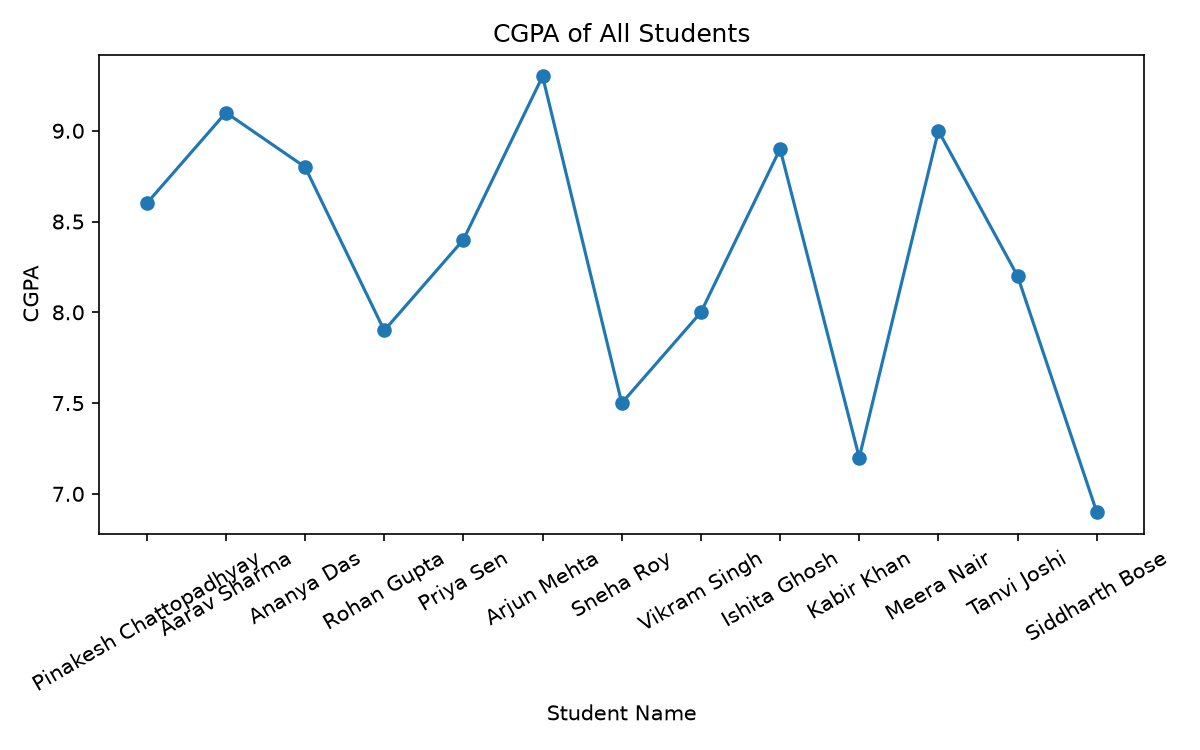

Here is the line chart showing the CGPA of every student in the database:

![CGPA of All Students](charts/cgpa_of_all_students.png)


In [16]:
print(run_agent("line chart of cgpa of all students"))